# ANN Class Imbalance Experiments

Compare SMOTE, random undersampling, and random oversampling for diabetes classification. Each strategy uses the same stratified train/validation/test split, feature preprocessing, ANN architecture, optimizer, batch size, epochs, and evaluation procedure. Resampling is applied only to the training split; validation and test distributions remain untouched.


## 1. Objective and experimental overview

The positive class (`diabetic = Yes`) is the minority class. We compare the three sampling strategies by minority-class precision, recall, and F1, alongside accuracy, ROC-AUC, PR-AUC, and confusion matrices. All models start from fresh weights with fixed random seeds.


## 2. Dataset preparation

Load the cleaned project dataset from disk so the experiment is reproducible offline. The Drive URL is retained as a fallback when the notebook is run outside this repository.


In [85]:
from pathlib import Path
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

def drive_to_direct_url(link: str) -> str:
    patterns = [r"/file/d/([a-zA-Z0-9_-]+)", r"id=([a-zA-Z0-9_-]+)", r"/open\?id=([a-zA-Z0-9_-]+)"]
    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            return f"https://drive.google.com/uc?id={match.group(1)}"
    raise ValueError("Invalid Google Drive link")

local_dataset = Path("cleaned_diabetes.csv")
if not local_dataset.exists():
    local_dataset = Path("diadb-training/cleaned_diabetes.csv")
if local_dataset.exists():
    df = pd.read_csv(local_dataset)
else:
    clean_dataset_drive_url = "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"
    df = pd.read_csv(drive_to_direct_url(clean_dataset_drive_url))

print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (5261, 13)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


## 3. Train/validation/test splitting

Use the same 68% training, 12% validation, and 20% test partitions as the established ANN workflow. Stratification preserves the original class proportions in all three partitions. The label encoder is fitted to the target labels only.


In [86]:
X = df.drop(columns="diabetic")
y_labels = df["diabetic"]
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE
)

print(f"Training rows: {len(y_train):,}; validation rows: {len(y_val):,}; test rows: {len(y_test):,}")
print(f"Label mapping: {dict(enumerate(label_encoder.classes_))} (positive class = 1)")


Training rows: 3,576; validation rows: 632; test rows: 1,053
Label mapping: {0: 'No', 1: 'Yes'} (positive class = 1)


## 4. Class distribution analysis

Record the original training distribution before any resampling. Validation and test labels are retained as split without modification for every experiment.


Original training distribution: {'No': 3343, 'Yes': 233}
Validation distribution: {'No': 591, 'Yes': 41}
Test distribution: {'No': 985, 'Yes': 68}


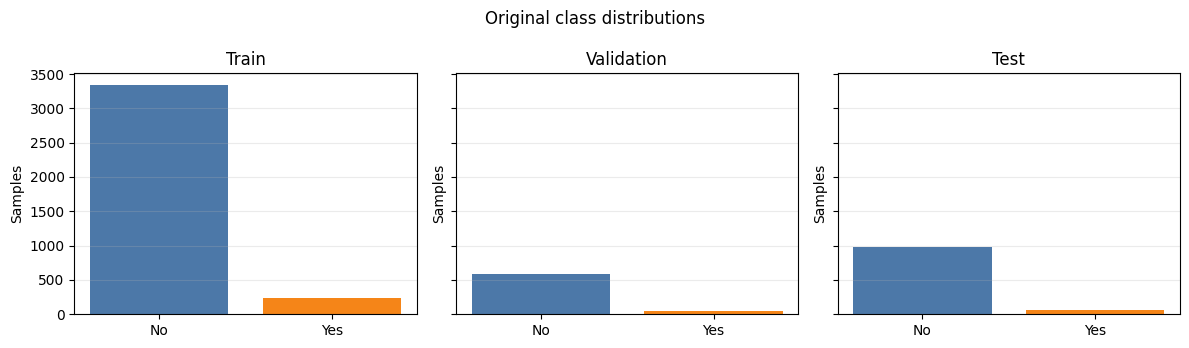

In [87]:
def class_counts(labels):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    return {label_encoder.classes_[index]: int(counts[index]) for index in (0, 1)}

original_train_distribution = class_counts(y_train)
print("Original training distribution:", original_train_distribution)
print("Validation distribution:", class_counts(y_val))
print("Test distribution:", class_counts(y_test))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, labels) in zip(axes, [("Train", y_train), ("Validation", y_val), ("Test", y_test)]):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    ax.bar(label_encoder.classes_, counts.values, color=["#4C78A8", "#F58518"])
    ax.set_title(name)
    ax.set_ylabel("Samples")
    ax.grid(axis="y", alpha=0.25)
plt.suptitle("Original class distributions")
plt.tight_layout()
plt.show()


## Shared training and evaluation procedure

Each strategy independently fits a fresh preprocessor on the original training rows only, transforms validation/test rows without fitting, and resamples only the transformed training data. A newly initialized ANN is trained with the same DataLoader settings and evaluated using the same 0.5 probability threshold. Validation performance is recorded as a check; the consolidated comparison uses the held-out test set.


In [88]:
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100

torch.set_num_threads(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

def build_preprocessor(training_features):
    numeric_cols = training_features.select_dtypes(include="number").columns
    categorical_cols = training_features.select_dtypes(exclude="number").columns
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

def make_loader(features, labels, shuffle, generator=None):
    if hasattr(features, "toarray"):
        features = features.toarray()
    features = np.asarray(features, dtype=np.float32)
    labels = np.asarray(labels, dtype=np.float32).reshape(-1, 1)
    dataset = TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

def build_model(input_features):
    return nn.Sequential(
        nn.Linear(input_features, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1),
    ).to(device)

def predict(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            logits = model(X_batch.to(device)).squeeze(1)
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).int()
            y_true.extend(y_batch.numpy().ravel())
            y_pred.extend(predictions.cpu().numpy().ravel())
            y_prob.extend(probabilities.cpu().numpy().ravel())
    return np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int), np.asarray(y_prob)

def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }

samplers = {
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "Random Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
}
results = {}
comparison_rows = []
def run_strategy(strategy_name, sampler):
    print(f"\n### {strategy_name}")
    # Fit preprocessing using only the original training subset.
    preprocessor = build_preprocessor(X_train)
    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    # Resample the training subset only.
    X_resampled, y_resampled = sampler.fit_resample(X_train_processed, y_train)
    resampled_distribution = class_counts(y_resampled)
    print("Original train distribution:", original_train_distribution)
    print("Resampled train distribution:", resampled_distribution)

    # Fixed initialization and loader seeds make runs reproducible and independent.
    run_seed = RANDOM_STATE
    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(run_seed)
    train_generator = torch.Generator().manual_seed(run_seed)

    train_loader = make_loader(X_resampled, y_resampled, shuffle=True, generator=train_generator)
    val_loader = make_loader(X_val_processed, y_val, shuffle=False)
    test_loader = make_loader(X_test_processed, y_test, shuffle=False)

    model = build_model(X_train_processed.shape[1])
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_loss)
        if (epoch + 1) % 20 == 0 or epoch == 0:
            print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {epoch_loss:.4f}")

    val_true, val_pred, val_prob = predict(model, val_loader)
    test_true, test_pred, test_prob = predict(model, test_loader)
    validation_metrics = calculate_metrics(val_true, val_pred, val_prob)
    test_metrics = calculate_metrics(test_true, test_pred, test_prob)
    results[strategy_name] = {
        "model": model,
        "train_losses": train_losses,
        "y_true": test_true,
        "y_pred": test_pred,
        "y_prob": test_prob,
        "confusion_matrix": confusion_matrix(test_true, test_pred, labels=[0, 1]),
        "validation_metrics": validation_metrics,
        "test_metrics": test_metrics,
        "original_distribution": original_train_distribution,
        "resampled_distribution": resampled_distribution,
    }
    comparison_rows.append({
        "Strategy": strategy_name,
        "Original train distribution": original_train_distribution,
        "Resampled train distribution": resampled_distribution,
        **test_metrics,
    })
    print("Validation metrics:", {k: round(v, 4) for k, v in validation_metrics.items()})
    print("Test metrics:", {k: round(v, 4) for k, v in test_metrics.items()})


Training device: cuda


### 5. SMOTE implementation and evaluation

SMOTE synthesizes minority examples from the training split. This run fits its own preprocessor and ANN model.


In [89]:
run_strategy("SMOTE", samplers["SMOTE"])



### SMOTE
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}
Epoch [1/100], Train Loss: 0.4655
Epoch [20/100], Train Loss: 0.2247
Epoch [40/100], Train Loss: 0.1458
Epoch [60/100], Train Loss: 0.1043
Epoch [80/100], Train Loss: 0.0824
Epoch [100/100], Train Loss: 0.0661
Validation metrics: {'Accuracy': 0.8829, 'Precision': 0.2676, 'Recall': 0.4634, 'F1-score': 0.3393, 'ROC-AUC': np.float64(0.7534), 'PR-AUC': np.float64(0.2733)}
Test metrics: {'Accuracy': 0.8794, 'Precision': 0.2389, 'Recall': 0.3971, 'F1-score': 0.2983, 'ROC-AUC': np.float64(0.7723), 'PR-AUC': np.float64(0.2691)}


### 6. Random Undersampling implementation and evaluation

Random undersampling reduces the majority training class. This run uses the same preprocessing and model settings with a fresh initialization.


In [90]:
run_strategy("Random Undersampling", samplers["Random Undersampling"])



### Random Undersampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 233, 'Yes': 233}
Epoch [1/100], Train Loss: 0.6776
Epoch [20/100], Train Loss: 0.4016
Epoch [40/100], Train Loss: 0.3600
Epoch [60/100], Train Loss: 0.3290
Epoch [80/100], Train Loss: 0.2897
Epoch [100/100], Train Loss: 0.2542
Validation metrics: {'Accuracy': 0.7706, 'Precision': 0.1905, 'Recall': 0.7805, 'F1-score': 0.3062, 'ROC-AUC': np.float64(0.8317), 'PR-AUC': np.float64(0.2582)}
Test metrics: {'Accuracy': 0.7863, 'Precision': 0.1822, 'Recall': 0.6618, 'F1-score': 0.2857, 'ROC-AUC': np.float64(0.8014), 'PR-AUC': np.float64(0.2346)}


### 7. Random Oversampling implementation and evaluation

Random oversampling duplicates minority training examples. This run also uses an independent preprocessor and freshly initialized model.


In [91]:
run_strategy("Random Oversampling", samplers["Random Oversampling"])



### Random Oversampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}
Epoch [1/100], Train Loss: 0.4799
Epoch [20/100], Train Loss: 0.2147
Epoch [40/100], Train Loss: 0.1166
Epoch [60/100], Train Loss: 0.0772
Epoch [80/100], Train Loss: 0.0520
Epoch [100/100], Train Loss: 0.0356
Validation metrics: {'Accuracy': 0.9019, 'Precision': 0.2766, 'Recall': 0.3171, 'F1-score': 0.2955, 'ROC-AUC': np.float64(0.7775), 'PR-AUC': np.float64(0.315)}
Test metrics: {'Accuracy': 0.8936, 'Precision': 0.2843, 'Recall': 0.4265, 'F1-score': 0.3412, 'ROC-AUC': np.float64(0.773), 'PR-AUC': np.float64(0.326)}


## 8. Consolidated performance comparison

The table reports test set metrics for all three strategies, plus original and resampled training class counts. Precision, recall, and F1-score are computed for the positive (diabetic) class.


,Original train distribution,Resampled train distribution,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Strategy,,,,,,,,
SMOTE,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8794,0.2389,0.3971,0.2983,0.7723,0.2691
Random Undersampling,"{'No': 3343, 'Yes': 233}","{'No': 233, 'Yes': 233}",0.7863,0.1822,0.6618,0.2857,0.8014,0.2346
Random Oversampling,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8936,0.2843,0.4265,0.3412,0.7730,0.3260


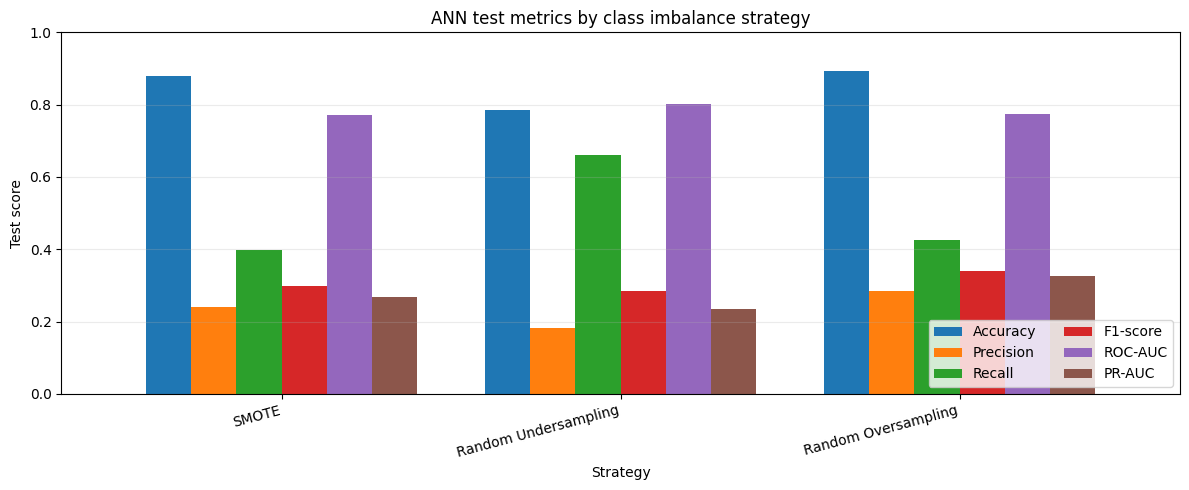

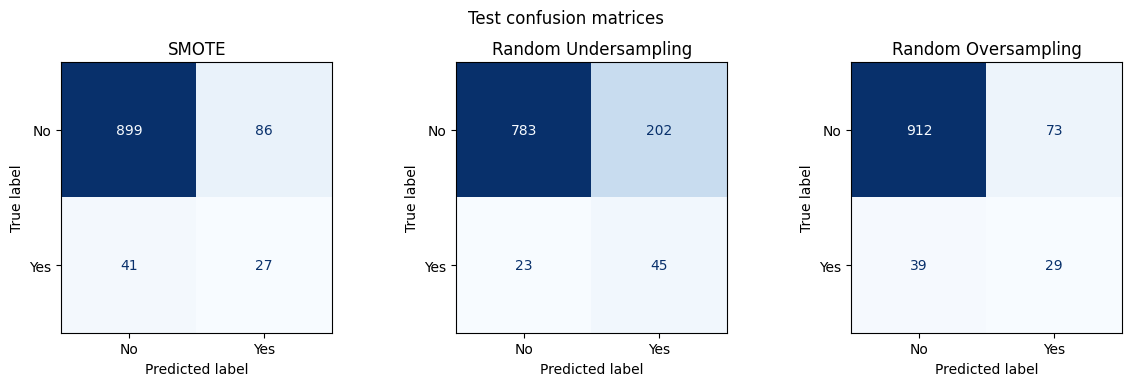

In [92]:
comparison = pd.DataFrame(comparison_rows).set_index("Strategy")
display(comparison.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}",
}))

metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
ax = comparison[metric_names].plot(kind="bar", figsize=(12, 5), ylim=(0, 1), width=0.8)
ax.set_ylabel("Test score")
ax.set_title("ANN test metrics by class imbalance strategy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(results), figsize=(12, 3.8))
for ax, (strategy_name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=label_encoder.classes_,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(strategy_name)
plt.suptitle("Test confusion matrices")
plt.tight_layout()
plt.show()


## 9. Results analysis and conclusion

Use the generated table and plots to compare the measured tradeoffs. Give particular attention to positive-class recall, precision, and F1-score: a higher recall can mean more diabetic cases detected, while precision reflects how many positive predictions are correct. ROC-AUC and PR-AUC summarize ranking performance across thresholds. No metric is entered manually; all results above are computed from the held-out test predictions.

The best strategy depends on the observed balance of these metrics and the application?s cost of missed cases versus false alarms. This comparison holds the data split, preprocessing, ANN architecture, optimizer, epochs, batch size, and evaluation threshold constant.
